# 01 — Anchor tables (rel-f1)

**Purpose.** The rerun builds task tables from each task's own query at the anchors
it chooses, instead of RelBench's three fixed splits. This notebook proves the
tables are the same as RelBench's wherever the anchors coincide. It also shows what
the uniform grid adds, and what the dense (Δw/4) and phase-shifted grids of the RQ4
ablation look like.

**Gate.**
1. Native train and val anchors reproduce RelBench's tables exactly.
2. Native test anchors differ only by entities RelBench counts as dangling.
3. The dense grid contains the native grid.
4. Phase-shifted grids share no anchor with the native grid.

In [1]:
DATASET = "rel-f1"
TASKS = ["driver-position", "driver-dnf", "driver-top3"]
SCALE = "smoke"
OUT = "notebooks/methodology/out"
THREADS = 8

In [2]:
# Parameters
SCALE = "smoke"
DEVICE = "cpu"


In [3]:
import json
import os
import sys
import time
from pathlib import Path

root = Path.cwd()
while not (root / "pyproject.toml").exists():
    root = root.parent
os.chdir(root)
sys.path.insert(0, str(root))

import matplotlib.pyplot as plt
import pandas as pd
import torch
from relbench.datasets import get_dataset
from relbench.tasks import get_task

from experiments.continuous_learning.chain_runner import DOWNLOAD
from redelex.continual.anchors import (
    grid_anchor_timestamps,
    labelled_anchor_range,
    make_anchor_table,
    native_anchor_timestamps,
)

torch.set_num_threads(THREADS)
out = Path(OUT)
out.mkdir(parents=True, exist_ok=True)
dataset = get_dataset(DATASET, download=DOWNLOAD.get(DATASET, False))
full_db = dataset.get_db(upto_test_timestamp=False)
trunc_db = dataset.get_db(upto_test_timestamp=True)
tasks = {t: get_task(DATASET, t) for t in TASKS}


def _sorted(df, task):
    return df.sort_values([task.time_col, task.entity_col], kind="stable").reset_index(drop=True)

/home/pelesjak/redelex/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:63: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


Loading Database object from /home/pelesjak/.cache/relbench/rel-f1/db...


Done in 0.42 seconds.
Loading Database object from /home/pelesjak/.cache/relbench/rel-f1/db...


Done in 0.29 seconds.


## 1. Native anchors reproduce RelBench's tables

In [4]:
equivalence = []
for name, task in tasks.items():
    for split in ("train", "val", "test"):
        db = full_db if split == "test" else trunc_db
        ts = native_anchor_timestamps(task, db, split)
        ours = make_anchor_table(task, db, ts).df
        native = _sorted(task.get_table(split, mask_input_cols=False).df, task)
        if split == "test":
            # RelBench counts entities against the truncated database.
            ours = ours[ours[task.entity_col] < len(trunc_db.table_dict[task.entity_table])].reset_index(drop=True)
        same = ours.shape == native.shape and ours.astype(str).equals(native.astype(str).reindex(columns=ours.columns))
        equivalence.append({"task": name, "split": split, "anchors": len(ts), "rows ours": len(ours),
                            "rows relbench": len(native), "identical": same})
equivalence = pd.DataFrame(equivalence)
equivalence

,task,split,anchors,rows ours,rows relbench,identical
0,driver-position,train,332,7453,7453,True
1,driver-position,val,30,499,499,True
2,driver-position,test,40,760,760,True
3,driver-dnf,train,665,11411,11411,True
4,driver-dnf,val,40,566,566,True
5,driver-dnf,test,40,702,702,True
6,driver-top3,train,665,1353,1353,True
7,driver-top3,val,40,588,588,True
8,driver-top3,test,40,726,726,True


## 2. What the uniform grid adds

Grid: every Δw through the RelBench validation timestamp, from the first anchor
with a complete history to the last anchor whose label window fits in the database.

In [5]:
grids, coverage = {}, []
for name, task in tasks.items():
    start, end = labelled_anchor_range(task, full_db)
    grid = grid_anchor_timestamps(dataset.val_timestamp, task.timedelta, start, end)
    t0 = time.perf_counter()
    table = make_anchor_table(task, full_db, grid).df
    secs = time.perf_counter() - t0
    grids[name] = table
    native = set()
    for split in ("train", "val", "test"):
        native |= set(native_anchor_timestamps(task, full_db if split == "test" else trunc_db, split))
    with_rows = set(pd.to_datetime(table[task.time_col].unique()))
    coverage.append({"task": name, "grid anchors": len(grid), "grid anchors with rows": len(with_rows),
                     "native anchors": len(native), "new anchors (gaps filled)": len(with_rows - native),
                     "rows": len(table), "build s": round(secs, 1)})
pd.DataFrame(coverage).set_index("task")

,grid anchors,grid anchors with rows,native anchors,new anchors (gaps filled),rows,build s
task,,,,,,
driver-position,447,349,402,72,9518,0.5
driver-dnf,895,588,745,142,15013,0.9
driver-top3,895,228,745,142,4973,0.3


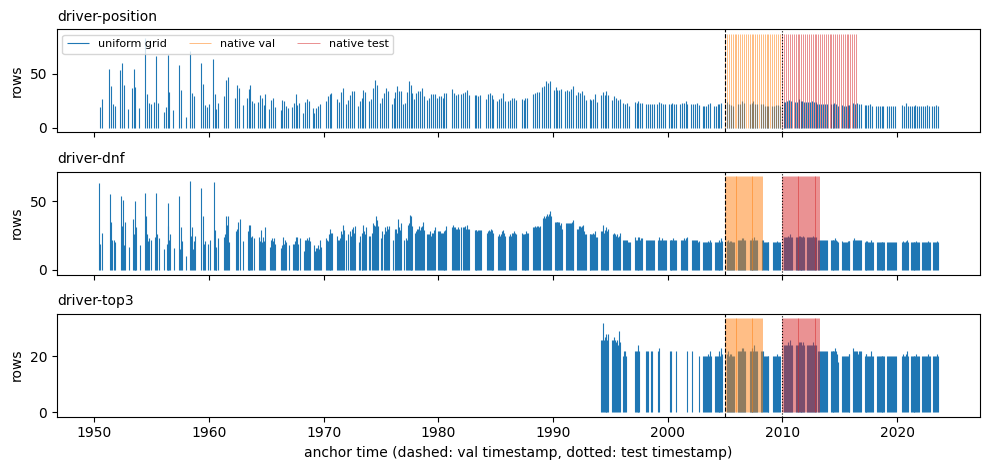

In [6]:
fig, axes = plt.subplots(len(tasks), 1, figsize=(10, 1.6 * len(tasks)), sharex=True)
for ax, (name, task) in zip(axes, tasks.items()):
    per_anchor = grids[name].groupby(task.time_col).size()
    ax.vlines(per_anchor.index, 0, per_anchor.values, color="tab:blue", lw=0.8, label="uniform grid")
    for split, color in (("val", "tab:orange"), ("test", "tab:red")):
        ts = native_anchor_timestamps(task, full_db if split == "test" else trunc_db, split)
        ax.vlines(ts, 0, per_anchor.max() * 1.05, color=color, lw=0.6, alpha=0.6, label=f"native {split}")
    ax.axvline(dataset.val_timestamp, color="k", ls="--", lw=0.8)
    ax.axvline(dataset.test_timestamp, color="k", ls=":", lw=0.8)
    ax.set_ylabel("rows")
    ax.set_title(name, fontsize=10, loc="left")
axes[0].legend(fontsize=8, ncol=3, loc="upper left")
axes[-1].set_xlabel("anchor time (dashed: val timestamp, dotted: test timestamp)")
fig.tight_layout()

## 3. Dense and phase-shifted grids (RQ4 ablation)

A Δw/4 stride gives updates shorter than a label window something to train on; the
labels of neighbouring anchors then overlap. Phase shifts test whether rankings
depend on where the anchors happen to sit.

In [7]:
variants = []
name = "driver-dnf" if "driver-dnf" in tasks else TASKS[0]
task = tasks[name]
start, end = labelled_anchor_range(task, full_db)
base = grid_anchor_timestamps(dataset.val_timestamp, task.timedelta, start, end)
dense = grid_anchor_timestamps(dataset.val_timestamp, task.timedelta / 4, start, end)
shifts = {f"{q}Δw": grid_anchor_timestamps(dataset.val_timestamp, task.timedelta, start, end, phase=task.timedelta * q)
          for q in (0.25, 0.5, 0.75)}
for label, ts in {"native stride": base, "dense Δw/4": dense, **{f"shift {k}": v for k, v in shifts.items()}}.items():
    if SCALE == "smoke" and label.startswith("shift") and label != "shift 0.5Δw":
        rows = None
    else:
        rows = len(make_anchor_table(task, full_db, ts).df)
    variants.append({"grid": label, "anchors": len(ts), "rows": rows,
                     "shares anchors with native": len(set(ts) & set(base))})
pd.DataFrame(variants).set_index("grid")

,anchors,rows,shares anchors with native
grid,,,
native stride,895,15013.0,895
dense Δw/4,3577,59923.0,895
shift 0.25Δw,894,NaN,0
shift 0.5Δw,894,15062.0,0
shift 0.75Δw,894,NaN,0


## Gate

In [8]:
assert equivalence["identical"].all(), equivalence[~equivalence["identical"]]
assert set(base) <= set(dense)
for k, ts in shifts.items():
    assert set(ts).isdisjoint(base), k
(out / f"01_anchor_tables_{DATASET}.json").write_text(
    json.dumps({"equivalence": equivalence.astype(str).to_dict(orient="records"), "coverage": coverage,
                "variants": variants}, indent=2, default=str)
)
print("GATE 01 PASSED")

GATE 01 PASSED
